# NB trajectory pipeline — methods walkthrough
## Section 1. Exploratory analysis of the healthy-donor data

The pipeline calls a clone **non-neutral** when its trajectory over a patient's samples
departs from what a clone of *constant* frequency would show, given the noise of the
measurement. Healthy donors define that noise: they are our neutral reference cohort.

Before fitting any model, this section looks at the donor data directly and asks five
questions. Each answer fixes one design choice of the pipeline:

| | Question | Design choice it motivates |
|---|---|---|
| 1.1 | What does a sample contain? | Depth $D_t$ and offsets |
| 1.2 | What is invisible to us? | A per-sample detection threshold $c_t$ → truncated / censored likelihood (Section 3) |
| 1.3 | Where is the information? | Abundance filters for estimating $\phi$ and for testing |
| 1.4 | How often is a clone seen again? | A cell-sampling **dropout** term (Section 3) |
| 1.5 | Which samples are failed libraries? | **Sample QC** relative to the same person, 2-of-4 rule |
| 1.6 | How noisy is each sample, and do donors drift? | Negative binomial, **per-sample $\phi_t$**, constant-frequency null |

A summary of the decisions is at the end (1.7).

**Data.** Six healthy donors (SEQTR, RNA-based TCRβ sequencing), 3–5 blood samples each
over 71–131 days; for the QC comparison in 1.5, the six patients as well. Counts are reads
per clonotype (amino-acid CDR3β), after the provider's upstream filter (frequency ≥ 1e-6).

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
from itertools import combinations, permutations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm as nb

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 160)

CUTOFF_FRAC = 1e-6           # upstream filter: frequency >= 1e-6 of in-frame reads

# plotting: one fixed colour per donor (same colour in every figure), recessive axes
DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY = '#8a8984'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#3d3c39', 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})

In [2]:
healthy_raw = pd.read_csv('../data/healthy_raw.csv', index_col=0)
patients_raw = pd.read_csv('../data/patients_raw.csv', index_col=0)

DONORS = sorted(healthy_raw['patient'].unique())
COLOR = dict(zip(DONORS, DONOR_COLORS))
short = lambda p: p.replace('_SEQTR', '').replace('_ReSeq', '')
print(len(healthy_raw), 'donor rows;', len(patients_raw), 'patient rows')
healthy_raw.head()

2969992 donor rows; 3193746 patient rows


,patient,day,clono,count,freq_in,D_t,c_t,lib_post
0,HD106_SEQTR,0,clono_1,226089,1.088219,20776057.0,21.0,19064838
1,HD106_SEQTR,0,clono_2,159926,0.769761,20776057.0,21.0,19064838
2,HD106_SEQTR,0,clono_3,141200,0.679628,20776057.0,21.0,19064838
3,HD106_SEQTR,0,clono_4,82582,0.397486,20776057.0,21.0,19064838
4,HD106_SEQTR,0,clono_5,70402,0.338861,20776057.0,21.0,19064838


## 1.1 What a sample contains

Each row is one clonotype in one sample:

* `count` — reads assigned to the clonotype. The data are **RNA**-based, so a read count
  mixes the number of cells of the clone with how many TCR transcripts each cell carries.
* `freq_in` — the clone's share of the sample's in-frame reads (in %), computed by the
  provider **before** their filter.
* `D_t` — the sample's in-frame depth, recovered as $D_t = \mathrm{median}(100\cdot
  \text{count}/\text{freq\_in})$. The sum of the counts we receive (`lib_post`) is smaller,
  because the filter removed the rarest clones; $D_t$ is the right denominator.
* `c_t` — the read cutoff implied by the filter (1.2).

Clone identifiers (`clono_1`, `clono_2`, …) are assigned **per person**, numbered in order
of first appearance. The same identifier in two people is not the same clone.

In [3]:
def sample_table(d):
    g = d.groupby(['patient', 'day'])
    t = g.agg(D_t=('D_t', 'first'), lib_post=('lib_post', 'first'), c_t=('c_t', 'first'),
              n_clones=('clono', 'size'), top_clone_share=('freq_in', 'max'))
    t['top_clone_share'] = t['top_clone_share'] / 100
    t['removed_by_filter'] = 1 - t['lib_post'] / t['D_t']
    return t

samples_h = sample_table(healthy_raw)
per_donor = samples_h.groupby('patient').agg(
    n_samples=('D_t', 'size'),
    days=('D_t', lambda s: ', '.join(map(str, s.index.get_level_values('day')))),
    depth_M=('D_t', lambda s: f"{s.min()/1e6:.1f}–{s.max()/1e6:.1f}"),
    clones_k=('n_clones', lambda s: f"{s.min()/1e3:.1f}–{s.max()/1e3:.0f}"),
    top_clone=('top_clone_share', lambda s: f"{s.min():.3f}–{s.max():.3f}"))
display(per_donor)
display(samples_h.style.format({'D_t': '{:,.0f}', 'lib_post': '{:,.0f}', 'c_t': '{:.0f}',
                                'n_clones': '{:,}', 'top_clone_share': '{:.4f}',
                                'removed_by_filter': '{:.3f}'}))

,n_samples,days,depth_M,clones_k,top_clone
patient,,,,,
HD106_SEQTR,4,"0, 46, 82, 131",13.2–20.8,166.7–214,0.009–0.012
HD197_SEQTR,4,"0, 46, 82, 131",15.1–17.7,179.5–213,0.006–0.011
HDBR01_SEQTR_ReSeq,4,"0, 21, 42, 126",10.2–21.3,101.8–133,0.003–0.003
HDBR02_SEQTR_ReSeq,3,"0, 48, 71",5.4–8.9,53.3–94,0.156–0.259
HDBR03_SEQTR_ReSeq,5,"0, 21, 35, 66, 84",4.9–10.7,71.6–157,0.017–0.041
HDBR06_SEQTR_ReSeq,4,"0, 21, 82, 105",5.1–11.5,0.7–85,0.036–0.242


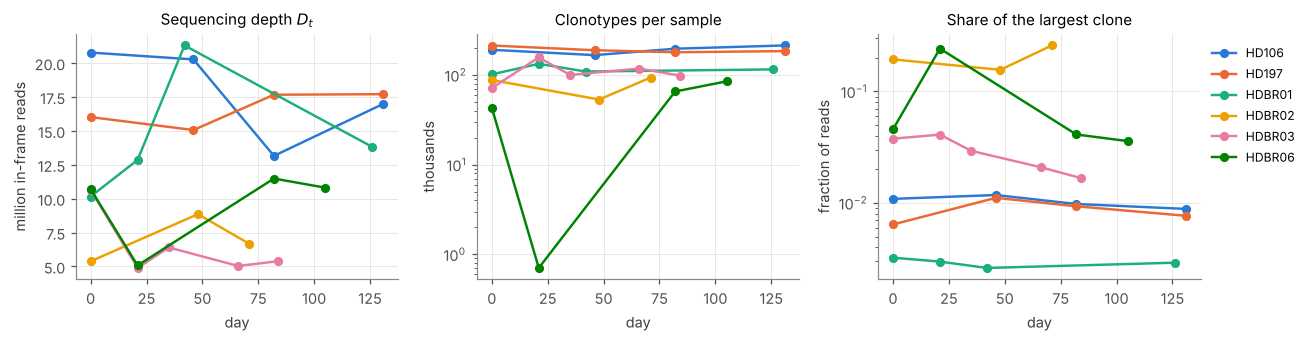

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for p in DONORS:
    s = samples_h.loc[p]
    kw = dict(color=COLOR[p], marker='o', label=short(p))
    axes[0].plot(s.index, s['D_t'] / 1e6, **kw)
    axes[1].plot(s.index, s['n_clones'] / 1e3, **kw)
    axes[2].plot(s.index, s['top_clone_share'], **kw)
axes[0].set(title='Sequencing depth $D_t$', xlabel='day', ylabel='million in-frame reads')
axes[1].set(title='Clonotypes per sample', xlabel='day', ylabel='thousands', yscale='log')
axes[2].set(title='Share of the largest clone', xlabel='day', ylabel='fraction of reads',
            yscale='log')
axes[2].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()

**What this shows.**

* Depth varies about **4-fold across samples** (4.9–21.3 M reads), within as well as between
  donors. A clone's read count is only comparable across samples after dividing by depth,
  so every model below uses an offset $L_t = D_t \times$ (TMM factor).
* Donors differ far more in **repertoire structure** than in depth: from about 43 k to
  214 k clonotypes per sample (one failed sample aside), and a largest clone holding from 0.3 % (HDBR01) to 26 %
  (HDBR02) of reads. Any per-sample quality criterion therefore has to be **relative to the
  same person**, not absolute (1.5).
* One sample is obviously different from everything else: **HDBR06 day 21**, with 706
  clonotypes against 43–85 k in the donor's other samples. We come back to it in 1.5.

## 1.2 The detection threshold: what we cannot see

The provider kept only clonotypes with frequency ≥ 1e-6 of the in-frame reads. In reads,
that is a per-sample cutoff

$$c_t = \lceil 10^{-6}\, D_t \rceil ,$$

so 5–22 reads in the donors, 3–12 in the patients. If this is right, the smallest count
in every sample equals $c_t$ exactly.

In [5]:
def threshold_check(d):
    t = d.groupby(['patient', 'day']).agg(D_t=('D_t', 'first'), c_t=('c_t', 'first'),
                                          min_count=('count', 'min'))
    t['min_count / D_t'] = t['min_count'] / t['D_t']
    return t

thr = pd.concat({'donors': threshold_check(healthy_raw),
                 'patients': threshold_check(patients_raw)})
print('samples where min count != c_t :', int((thr['min_count'] != thr['c_t']).sum()),
      'of', len(thr))
print('min count / D_t ranges from', f"{thr['min_count / D_t'].min():.3g}",
      'to', f"{thr['min_count / D_t'].max():.3g}")
thr.groupby(level=0)[['c_t']].agg(['min', 'max'])

samples where min count != c_t : 0 of 60
min count / D_t ranges from 1e-06 to 1.3e-06


c_t      
          min   max
donors    5.0  22.0
patients  3.0  12.0

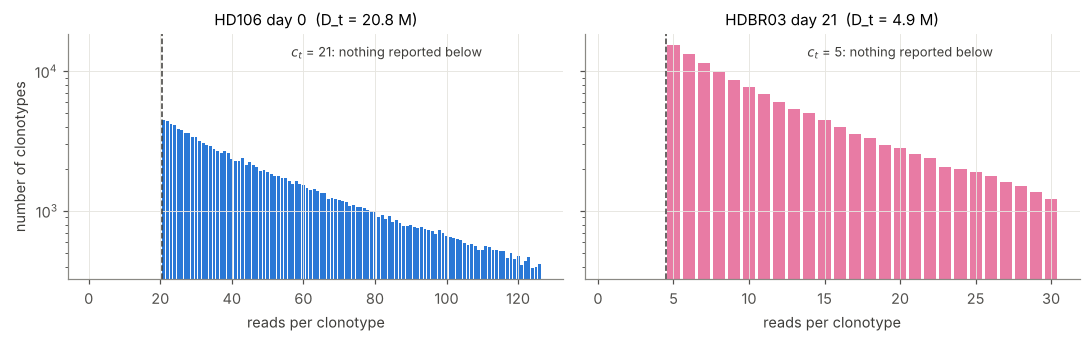

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (p, day) in zip(axes, [('HD106_SEQTR', 0), ('HDBR03_SEQTR_ReSeq', 21)]):
    s = healthy_raw[(healthy_raw['patient'] == p) & (healthy_raw['day'] == day)]
    c = int(s['c_t'].iloc[0])
    k = np.arange(1, 6 * c + 1)
    n_k = s['count'].value_counts().reindex(k, fill_value=0)
    ax.bar(k, n_k.values, width=0.8, color=COLOR[p])
    ax.axvline(c - 0.5, color='#3d3c39', lw=1, ls='--')
    ax.annotate(f'$c_t$ = {c}: nothing reported below', xy=(c - 0.5, n_k.max()),
                xytext=(0.45, 0.96), textcoords='axes fraction', va='top', fontsize=8.5,
                color='#3d3c39')
    ax.set(title=f'{short(p)} day {day}  (D_t = {s["D_t"].iloc[0]/1e6:.1f} M)',
           xlabel='reads per clonotype', yscale='log')
axes[0].set_ylabel('number of clonotypes')
fig.tight_layout()

**What this shows.** In all 60 samples (24 donor, 36 patient) the smallest observed count
equals $c_t$, and the smallest frequency is $10^{-6}$ to within rounding. The number of
clonotypes keeps **increasing as the count decreases, all the way down to $c_t$**: the
distribution is cut where it is steepest, so most clonotypes of a repertoire sit below
the threshold and are never reported.

Two consequences shape the likelihood (Section 3):

1. **Observed counts are conditional on detection.** A clone whose expected count is near
   $c_t$ is reported only when it fluctuates upwards, so its observed counts overstate its
   mean. Fitting the noise on detected counts must use the NB **truncated** at $c_t$,
   $P(X = x \mid X \ge c_t)$, or the dispersion is biased.
2. **A missing clone is not a zero.** It means $X < c_t$, and $c_t$ differs between
   samples (5–22 reads in donors). The same clone at the same frequency can be visible in
   a deep sample and invisible in a shallow one. In the patient test, a miss contributes
   $P(X \le c_t - 1)$ (a **censored** observation), never $P(X = 0)$.

## 1.3 Where the information is: the clone-size distribution

In [7]:
f = healthy_raw.assign(freq=healthy_raw['count'] / healthy_raw['D_t'])
band = pd.cut(f['freq'], [0, 1e-5, 1e-4, 1],
              labels=['1e-6 – 1e-5', '1e-5 – 1e-4', '≥ 1e-4'], right=False)
bands = (f.groupby(['patient', band], observed=False)
          .agg(clones=('clono', 'size'), reads=('count', 'sum')))
bands = bands / bands.groupby(level=0).transform('sum')
display(bands.unstack().style.format('{:.1%}').set_caption(
    'Share of clonotypes and of reads by frequency band (all samples of each donor)'))

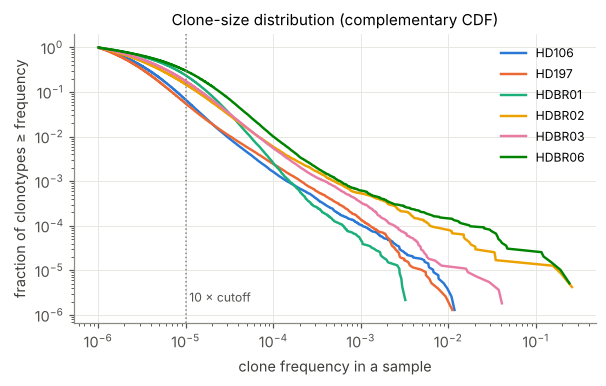

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for p in DONORS:
    x = np.sort(f.loc[f['patient'] == p, 'freq'].to_numpy())
    ccdf = 1 - np.arange(len(x)) / len(x)
    ax.plot(x, ccdf, color=COLOR[p], label=short(p))
ax.axvline(1e-5, color=GREY, lw=1, ls=':')
ax.text(1.1e-5, 2e-6, '10 × cutoff', color='#52514e', fontsize=8)
ax.set(xscale='log', yscale='log', xlabel='clone frequency in a sample',
       ylabel='fraction of clonotypes ≥ frequency',
       title='Clone-size distribution (complementary CDF)')
ax.legend(fontsize=8)
fig.tight_layout()

**What this shows.** The repertoire is extremely heavy-tailed. **70–94 % of the reported
clonotypes lie within 10× of the cutoff** (frequency below 1e-5), yet they hold only
16–59 % of the reads. A clone counted 6 or 12 times cannot show a change: its counts are
dominated by sampling noise and it is often not detected at all (1.4).

Two filters follow, both on overall abundance (never on the trajectory, so they do not
bias the test):

* the **dispersion** $\phi$ is estimated from clones at ≥ 10× the cutoff, where the
  truncation correction is small and the counts carry information on the noise
  (Section 2);
* the **test** is applied to clones with average frequency ≥ 1e-5 over the person's
  samples; below that, simulated power is essentially zero, and including those clones
  only makes the multiple-testing correction harsher (Section 4).

## 1.4 How often is a clone seen again?

Take every pair of samples $(i, j)$ of a donor. For the clones detected in $i$, binned by
their frequency in $i$, what fraction is also detected in $j$? For comparison, the grey
line gives the fraction expected if **read sampling were the only noise**: the clone keeps
its frequency, its count in $j$ is NB with mean $f_i L_j$ and $\phi = 2$ (about the donors'
value, Section 2), and it is detected if the count reaches $c_j$.

patient,HD106,HD197,HDBR01,HDBR02,HDBR03,HDBR06
f,,,,,,
0.000007,0.18,0.30,0.10,0.27,0.21,0.14
0.000013,0.31,0.52,0.13,0.39,0.30,0.18
0.000024,0.53,0.78,0.19,0.57,0.44,0.26
0.000042,0.78,0.93,0.30,0.77,0.64,0.38
0.000075,0.93,0.99,0.47,0.92,0.82,0.54
0.000133,0.98,1.00,0.67,0.98,0.91,0.74
0.000237,0.99,1.00,0.84,0.99,0.97,0.89


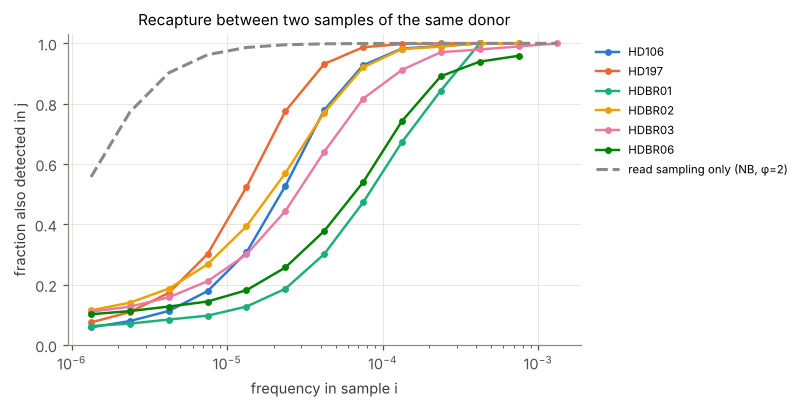

In [9]:
edges = 10 ** np.arange(-6, -2.49, 0.25)

def recapture_curve(d, phi=2.0):
    rows = []
    for p, g in d.groupby('patient'):
        days = np.sort(g['day'].unique())
        per = g.groupby('day')[['lib', 'c_t']].first().reindex(days)
        X = (g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum',
                           fill_value=0).reindex(columns=days, fill_value=0).to_numpy(float))
        L, c = per['lib'].to_numpy(), per['c_t'].to_numpy()
        for i, j in permutations(range(len(days)), 2):
            det = X[:, i] > 0
            fi, hit = X[det, i] / L[i], X[det, j] > 0
            b = np.digitize(fi, edges)
            for k in np.unique(b):
                s = b == k
                if s.sum() < 20 or k == 0 or k == len(edges):
                    continue
                mu = fi[s] * L[j]
                rows.append({'patient': p, 'f': np.sqrt(edges[k - 1] * edges[k]),
                             'n': int(s.sum()), 'observed': hit[s].mean(),
                             'reads_only': stats.nbinom.sf(c[j] - 1, phi, phi / (phi + mu)).mean()})
    r = pd.DataFrame(rows)
    w = lambda col: (lambda x: np.average(x[col], weights=x['n']))
    return (r.groupby(['patient', 'f'])
             .apply(lambda x: pd.Series({'observed': w('observed')(x),
                                         'reads_only': w('reads_only')(x), 'n': x['n'].sum()}))
             .reset_index())

# QC (1.5) removes one failed donor sample; offsets need TMM (lib = D_t x TMM factor)
qc_d = sample_qc(healthy_raw)
d_qc = nb.attach_offset(tmm_normalize(drop_failed_samples(healthy_raw, qc_d)))
rc = recapture_curve(d_qc)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
for p in DONORS:
    r = rc[rc['patient'] == p]
    ax.plot(r['f'], r['observed'], color=COLOR[p], marker='o', ms=3.5, label=short(p))
ro = rc.groupby('f')['reads_only'].mean()
ax.plot(ro.index, ro.values, color=GREY, ls='--', lw=2, label='read sampling only (NB, φ=2)')
ax.set(xscale='log', xlabel='frequency in sample i', ylabel='fraction also detected in j',
       title='Recapture between two samples of the same donor', ylim=(0, 1.03))
ax.legend(fontsize=7.5, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()
display(rc.pivot(index='f', columns='patient', values='observed')
          .rename(columns=short).round(2).loc[lambda t: (t.index > 5e-6) & (t.index < 3e-4)])

The curve plugs in the frequency observed in $i$, which overstates the true frequency of
clones near the cutoff (they were selected for being detected). A cleaner check, from the
pipeline's `estimate_dropout_N`: for each sample $t$, take the clones seen in at least two
of the person's **other** samples, estimate their abundance from those samples only
(truncated NB), and compare the fraction detected at $t$ with the fraction predicted by the
NB alone. Nothing about sample $t$ enters the prediction.

In [10]:
ps_don = nb.fit_phi_per_sample(d_qc)                  # per-sample phi (Section 2)
phi_spec = ps_don.rename(columns={'phi_sample': 'phi'})
Nt_don = nb.estimate_dropout_N(d_qc, phi=phi_spec)
det_tab = Nt_don[['patient', 'day', 'n_clones', 'obs_detect_rate',
                  'pred_detect_rate_nb_only', 'pred_detect_rate']].rename(columns={
    'n_clones': 'clones checked', 'obs_detect_rate': 'observed',
    'pred_detect_rate_nb_only': 'predicted: reads only',
    'pred_detect_rate': 'predicted: reads + cell sampling'})
display(det_tab.round(3))
print('observed detection   :', det_tab['observed'].min().round(2), '–',
      det_tab['observed'].max().round(2))
print('NB-only prediction   :', det_tab['predicted: reads only'].min().round(2), '–',
      det_tab['predicted: reads only'].max().round(2))

,patient,day,clones checked,observed,predicted: reads only,predicted: reads + cell sampling
0,HD106_SEQTR,0,41905,0.438,0.792,0.409
1,HD106_SEQTR,46,40879,0.475,0.852,0.442
2,HD106_SEQTR,82,39716,0.499,0.821,0.465
3,HD106_SEQTR,131,35760,0.593,0.856,0.546
4,HD197_SEQTR,0,47102,0.565,0.840,0.529
5,HD197_SEQTR,46,46086,0.598,0.862,0.562
6,HD197_SEQTR,82,49417,0.520,0.850,0.493
7,HD197_SEQTR,131,49065,0.531,0.853,0.498
8,HDBR01_SEQTR_ReSeq,0,24493,0.406,0.868,0.371
9,HDBR01_SEQTR_ReSeq,21,21463,0.509,0.869,0.459


observed detection   : 0.33 – 0.76
NB-only prediction   : 0.79 – 0.89


**What this shows.** Read-sampling noise alone predicts that a clone at 1e-5 (10× the
cutoff) is recaptured almost always (about 98 %). Observed recapture at that frequency is
**13–52 %**, and it only approaches 1 at about 1e-4 (4e-4 for HDBR01). In the leave-one-
sample-out check, the NB alone predicts detection rates of 0.79–0.89; the observed rates
are **0.33–0.76**.

So most misses happen **before sequencing**. A blood sample contains a finite number of
T cells, and a clone at 1e-5 is represented by a handful of them: in some samples it is
simply not drawn. This is cell sampling, and it is not part of the NB read noise.

Consequences:

* **Absence is weak evidence of contraction.** A model that only knows read noise would
  read most misses as "the clone disappeared". The patient test therefore includes a
  **dropout** term: a clone with frequency $\lambda$ is absent from sample $t$ with
  probability $e^{-N_t\lambda}$, where $N_t$ (the effective number of cells sampled) is
  estimated per sample (Section 3). With it, the predicted detection rates (last column)
  come within 0.02–0.07 of the observed ones.
* **Donor dispersion is estimated on detected counts only** (sparse data, no zero-filling).
  Treating the misses as zeros would attribute cell-sampling losses to the read noise and
  drive $\phi$ towards 0.

## 1.5 Sample QC: which samples are failed libraries?

Section 1.1 showed that donors differ by an order of magnitude in diversity and
clonality, so absolute thresholds would flag whole people. Each metric is instead
expressed **relative to the median of the same person's other samples** (`*_rel` = 1 means
typical for that person):

| metric | what a failed library looks like | fails if |
|---|---|---|
| `n_clones_rel` — clonotypes reported | few templates amplified | < 0.2 |
| `top_share_rel` — share of the largest clone | one clone dominates by PCR jackpotting | > 5 |
| `reads_per_clone_rel` — reads / clonotype | reads spread over few molecules | > 5 |
| `recapture_rel` — fraction of the person's *anchor* clones detected | the sample misses clones present everywhere else | < 0.6 |

Anchor clones: detected in **all** the person's other samples with mean frequency ≥ 1e-5.
A sample is **dropped if it fails at least two** criteria; a single failure is flagged
for review but kept.

The thresholds are set from the donors: the question is how far a healthy, well-sequenced
sample can drift from its siblings on each metric.

In [11]:
qc_p = sample_qc(patients_raw)
qc = pd.concat([qc_d.assign(cohort='donor'), qc_p.assign(cohort='patient')], ignore_index=True)
metrics = {'n_clones_rel': ('< 0.2', 0.2), 'top_share_rel': ('> 5', 5),
           'reads_per_clone_rel': ('> 5', 5), 'recapture_rel': ('< 0.6', 0.6)}
show = ['cohort', 'patient', 'day', *metrics, 'n_anchors', 'n_fails', 'drop', 'review']
display(qc.loc[qc['n_fails'] > 0, show].round(3))

kept = qc[~qc['drop']]
rng = kept.groupby('cohort')[list(metrics)].agg(['min', 'max']).T.unstack()
display(rng.round(2).style.set_caption('Range of each metric over the samples that pass QC'))

,cohort,patient,day,n_clones_rel,top_share_rel,reads_per_clone_rel,recapture_rel,n_anchors,n_fails,drop,review
21,donor,HDBR06_SEQTR_ReSeq,21,0.011,5.757,41.983,0.009,4488,4,True,False
24,patient,BR032,0,1.303,0.146,0.466,0.027,1894,1,False,True
31,patient,BR037,28,1.704,12.972,0.363,0.033,409,2,True,False
38,patient,BR046,120,0.635,6.546,2.036,0.864,2564,1,False,True
51,patient,BR052,164,0.045,1.038,12.775,0.615,13,2,True,False
52,patient,BR052,192,0.100,0.813,6.477,0.533,15,3,True,False
57,patient,BR054,141,0.303,7.260,1.856,0.005,2828,2,True,False


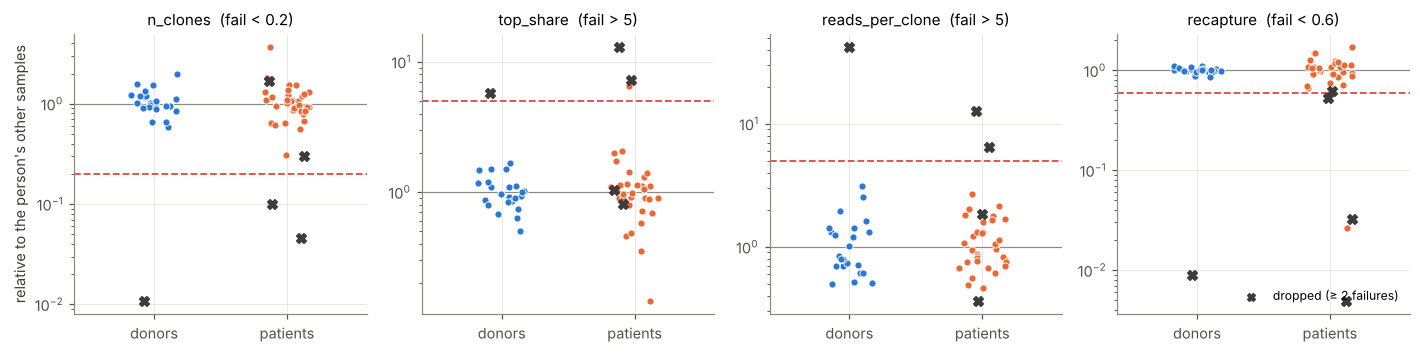

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
rs = np.random.default_rng(1)
for ax, (m, (lab, thr_v)) in zip(axes, metrics.items()):
    for k, coh in enumerate(['donor', 'patient']):
        s = qc[qc['cohort'] == coh]
        x = k + rs.uniform(-0.18, 0.18, len(s))
        y = s[m].clip(lower=1e-3)
        ax.scatter(x[~s['drop']], y[~s['drop']], s=22, color='#2a78d6' if coh == 'donor'
                   else '#eb6834', edgecolor='white', linewidth=0.6, zorder=3)
        ax.scatter(x[s['drop']], y[s['drop']], s=40, marker='X', color='#3d3c39', zorder=4)
    ax.axhline(thr_v, color='#e34948', lw=1.2, ls='--')
    ax.axhline(1, color=GREY, lw=0.8)
    ax.set(yscale='log', xticks=[0, 1], xticklabels=['donors', 'patients'],
           title=f'{m.replace("_rel", "")}  (fail {lab})', xlim=(-0.6, 1.6))
axes[0].set_ylabel('relative to the person\'s other samples')
axes[-1].scatter([], [], marker='X', color='#3d3c39', label='dropped (≥ 2 failures)')
axes[-1].legend(fontsize=8, loc='lower right')
fig.tight_layout()

**What this shows.**

* Over the donor samples that pass QC, every metric stays within a factor of about 3 of
  the person's typical value (`n_clones_rel` 0.59–1.97, `top_share_rel` 0.51–1.66,
  `reads_per_clone_rel` 0.50–3.11, `recapture_rel` 0.87–1.11). The thresholds sit outside
  that range with a margin, so ordinary sample-to-sample variation never fails.
* **HDBR06 day 21** fails all four, by one to two orders of magnitude: 1 % of the donor's
  usual clonotypes, 42× the reads per clonotype, and it recaptures 0.9 % of the anchor
  clones. That is a failed library, not biology, and it is the only donor sample removed.
* In the patients, the same rule removes **BR037 day 28, BR052 days 164 and 192, and BR054
  day 141**; each fails two or more criteria together.
* **Why two failures and not one.** The single-failure samples are exactly the cases we
  must keep. BR046 day 120 has a largest clone 6.5× its usual share: a large clonal
  expansion, i.e. the signal the pipeline is looking for. BR032 day 0 recaptures only 3 %
  of the anchor clones but looks normal otherwise: a low-input sample, which the dropout
  term handles (Section 3) rather than a broken library. One extreme metric can be biology;
  two concordant ones point to the library.
* `recapture_rel` needs anchors. When another sample of the same person failed, few
  anchors remain (column `n_anchors`) and the metric is noisier; this is why BR052's
  kept samples show values above 1.

## 1.6 How noisy is each sample, and do healthy repertoires drift?

Consider a clone with **constant** frequency $\lambda$ and two samples $i, j$ of the same
person, with offsets $L_i, L_j$. Its log fold change is

$$d_{ij} = \log\frac{x_j}{L_j} - \log\frac{x_i}{L_i}.$$

Under a negative binomial with per-sample dispersion $\phi_t$
($\mathrm{Var}\,x_t = \mu_t + \mu_t^2/\phi_t$), for counts well above the cutoff

$$\mathrm{Var}(d_{ij}) \;\approx\; \underbrace{\frac{1}{\mu_i} + \frac{1}{\mu_j}}_{\text{read sampling (Poisson)}}
\;+\; \underbrace{v_i + v_j}_{\text{sample noise}} \;+\; \underbrace{\kappa\,|t_j - t_i|}_{\text{drift}},$$

where $v_t \approx \psi_1(\phi_t)$ (the variance of the log of a Gamma($\phi_t$) variable)
is the multiplicative noise each sample adds, and $\kappa$ is a biological drift rate:
healthy clones wandering in frequency, so that samples further apart differ more.

This gives three hypotheses to check, without fitting any NB:

* **H0 — read sampling only** ($v = 0$, Poisson): the spread of $d$ should fall to almost
  zero for abundant clones.
* **H1 — one noise level per person** ($v_i = v_{\text{person}}$): every pair of samples
  of a person should have the same spread.
* **H2 — per-sample noise** ($v_t$ free): pairs that share a noisy sample are all wider.

and the drift term $\kappa$ on top.

First, one donor's three pairs, clone by clone. The grey band is ±2 SD of read sampling
alone.

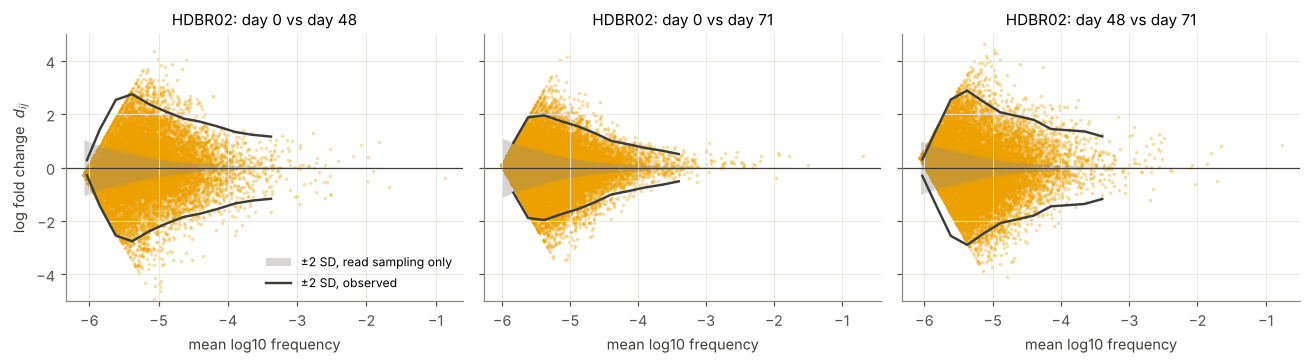

In [13]:
def pair_arrays(g, i_day, j_day):
    per = g.groupby('day')[['lib', 'c_t', 'D_t']].first()
    X = g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum', fill_value=0)
    xi, xj = X[i_day].to_numpy(float), X[j_day].to_numpy(float)
    both = (xi > 0) & (xj > 0)
    xi, xj = xi[both], xj[both]
    Li, Lj = per.loc[i_day, 'lib'], per.loc[j_day, 'lib']
    a = 0.5 * (np.log(xi / Li) + np.log(xj / Lj))            # mean log frequency
    d = np.log(xj / Lj) - np.log(xi / Li)
    pois = np.sqrt(1 / xi + 1 / xj)
    return a, d, pois

p = 'HDBR02_SEQTR_ReSeq'
g = d_qc[d_qc['patient'] == p]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (i, j) in zip(axes, combinations(sorted(g['day'].unique()), 2)):
    a, d, pois = pair_arrays(g, i, j)
    o = np.argsort(a)
    ax.scatter(a / np.log(10), d, s=2, color=COLOR[p], alpha=0.25, rasterized=True)
    ax.fill_between(a[o] / np.log(10), -2 * pois[o], 2 * pois[o], color=GREY, alpha=0.35,
                    lw=0, label='±2 SD, read sampling only')
    # observed spread: robust SD of d in abundance bins (only bins with >= 30 clones)
    bins = np.arange(-6, -1.5, 0.25) * np.log(10)
    k = np.digitize(a, bins)
    mid, sd = [], []
    for b in np.unique(k):
        sel = k == b
        if sel.sum() >= 30:
            mid.append(np.median(a[sel]) / np.log(10))
            sd.append(1.4826 * np.median(np.abs(d[sel] - np.median(d[sel]))))
    mid, sd = np.array(mid), np.array(sd)
    ax.plot(mid, 2 * sd, color='#3d3c39', lw=1.6, label='±2 SD, observed')
    ax.plot(mid, -2 * sd, color='#3d3c39', lw=1.6)
    ax.axhline(0, color='#3d3c39', lw=0.8)
    ax.set(title=f'{short(p)}: day {i} vs day {j}', xlabel='mean log10 frequency',
           ylim=(-5, 5))
axes[0].set_ylabel('log fold change  $d_{ij}$')
axes[0].legend(fontsize=8, loc='lower right')
fig.tight_layout()

The observed spread (dark lines) does not collapse onto the grey band for abundant
clones: it levels off at a plateau far above read sampling (**H0 is rejected**, the counts
are overdispersed). And the plateau is clearly wider in both pairs that contain day 48
than in day 0 vs day 71 (**against H1**). (The wedge at the far left is the detection
threshold: a clone near the cutoff in both samples cannot have a large fold change.)

Now all pairs of all donors. For each pair we keep clones detected in both samples with
pair-average frequency ≥ 20× the cutoff (the selection is on the sum, which is nearly
independent of the difference), and estimate the spread robustly,
$\widehat{\mathrm{Var}}(d) = (1.4826\cdot\mathrm{MAD})^2$, so that a minority of genuinely
changing clones does not inflate it. The **excess** over read sampling is
$E_{ij} = \widehat{\mathrm{Var}}(d) - \overline{1/x_i + 1/x_j}$.

In [14]:
def pairwise_excess(d, floor_mult=20):
    rows = []
    for p, g in d.groupby('patient'):
        days = np.sort(g['day'].unique())
        per = g.groupby('day')[['lib', 'c_t', 'D_t']].first().reindex(days)
        X = (g.pivot_table(index='clono', columns='day', values='count', aggfunc='sum',
                           fill_value=0).reindex(columns=days, fill_value=0).to_numpy(float))
        L = per['lib'].to_numpy()
        thr_f = (per['c_t'] / per['D_t']).to_numpy()
        for i, j in combinations(range(len(days)), 2):
            xi, xj = X[:, i], X[:, j]
            fpair = (xi / L[i] + xj / L[j]) / 2
            keep = (xi > 0) & (xj > 0) & (fpair >= floor_mult * max(thr_f[i], thr_f[j]))
            dd = np.log(xj[keep] / L[j]) - np.log(xi[keep] / L[i])
            var_d = (1.4826 * np.median(np.abs(dd - np.median(dd)))) ** 2
            pois = np.mean(1 / xi[keep] + 1 / xj[keep])
            rows.append({'patient': p, 'day_i': days[i], 'day_j': days[j],
                         'gap_days': days[j] - days[i], 'n_clones': int(keep.sum()),
                         'median_d': np.median(dd), 'var_d': var_d, 'read_sampling': pois,
                         'excess': var_d - pois})
    return pd.DataFrame(rows)

pw = pairwise_excess(d_qc)
display(pw.round(3))

,patient,day_i,day_j,gap_days,n_clones,median_d,var_d,read_sampling,excess
0,HD106_SEQTR,0,46,46,2360,0.149,0.857,0.004,0.853
1,HD106_SEQTR,0,82,82,2239,0.090,0.561,0.005,0.556
2,HD106_SEQTR,0,131,131,2528,0.188,0.657,0.004,0.653
3,HD106_SEQTR,46,82,36,2444,-0.029,0.435,0.004,0.431
4,HD106_SEQTR,46,131,85,2624,0.010,0.371,0.003,0.367
5,HD106_SEQTR,82,131,49,2571,0.056,0.304,0.005,0.300
6,HD197_SEQTR,0,46,46,2809,0.149,0.190,0.004,0.187
7,HD197_SEQTR,0,82,82,2704,0.100,0.205,0.003,0.202
8,HD197_SEQTR,0,131,131,2598,0.057,0.212,0.003,0.209
9,HD197_SEQTR,46,82,36,2926,-0.061,0.217,0.003,0.214


**Decomposition.** We fit $E_{ij} = v_i + v_j + \kappa\,(t_j - t_i)$ by weighted least
squares over all 34 donor pairs (one $v$ per sample, one $\kappa$ shared by all donors;
weights $\propto n_{ij}/E_{ij}^2$, the inverse variance of a variance estimate), and
compare it with H1, where each person has a single $v$.

In [15]:
def fit_excess(pw, per_sample=True):
    samples = sorted(set(zip(pw['patient'], pw['day_i'])) | set(zip(pw['patient'], pw['day_j'])))
    if per_sample:
        idx = {s: k for k, s in enumerate(samples)}
        A = np.zeros((len(pw), len(samples)))
        for r, (p, a, b) in enumerate(zip(pw['patient'], pw['day_i'], pw['day_j'])):
            A[r, idx[(p, a)]] += 1
            A[r, idx[(p, b)]] += 1
        names = samples
    else:
        names = sorted(pw['patient'].unique())
        A = np.column_stack([2.0 * (pw['patient'] == p) for p in names])
    A = np.column_stack([A, pw['gap_days'].to_numpy(float)])
    w = (pw['n_clones'] / (2 * np.maximum(pw['excess'], 0.05) ** 2)).to_numpy()
    sw = np.sqrt(w)
    beta, *_ = np.linalg.lstsq(A * sw[:, None], pw['excess'].to_numpy() * sw, rcond=None)
    fitted = A @ beta
    rss = float((w * (pw['excess'].to_numpy() - fitted) ** 2).sum())
    dof = len(pw) - A.shape[1]
    cov = rss / dof * np.linalg.pinv((A * w[:, None]).T @ A)
    return {'beta': beta, 'se': np.sqrt(np.diag(cov)), 'names': names, 'fitted': fitted,
            'rss': rss, 'dof': dof}

H2 = fit_excess(pw, per_sample=True)
H1 = fit_excess(pw, per_sample=False)
F = ((H1['rss'] - H2['rss']) / (H1['dof'] - H2['dof'])) / (H2['rss'] / H2['dof'])
p_F = stats.f.sf(F, H1['dof'] - H2['dof'], H2['dof'])
print(f"H1 (one v per person): weighted RSS = {H1['rss']:.0f} on {H1['dof']} df")
print(f"H2 (one v per sample): weighted RSS = {H2['rss']:.0f} on {H2['dof']} df")
print(f"F = {F:.1f} on ({H1['dof'] - H2['dof']}, {H2['dof']}) df,  p = {p_F:.1e}")
print(f"drift kappa = {H2['beta'][-1]:.2e} ± {H2['se'][-1]:.2e} per day  (H2)")

v_t = pd.DataFrame(H2['names'], columns=['patient', 'day'])
v_t['v_t'], v_t['se'] = H2['beta'][:-1], H2['se'][:-1]
v_t['v_rel'] = v_t['v_t'] / v_t.groupby('patient')['v_t'].transform('median')
display(v_t.round(3))

H1 (one v per person): weighted RSS = 3787 on 27 df
H2 (one v per sample): weighted RSS = 195 on 10 df
F = 10.8 on (17, 10) df,  p = 2.7e-04
drift kappa = -3.27e-05 ± 5.44e-04 per day  (H2)


,patient,day,v_t,se,v_rel
0,HD106_SEQTR,0,0.484,0.062,2.332
1,HD106_SEQTR,46,0.263,0.040,1.264
2,HD106_SEQTR,82,0.153,0.035,0.736
3,HD106_SEQTR,131,0.136,0.045,0.657
4,HD197_SEQTR,0,0.075,0.034,0.656
5,HD197_SEQTR,46,0.112,0.017,0.974
6,HD197_SEQTR,82,0.118,0.020,1.026
7,HD197_SEQTR,131,0.153,0.039,1.336
8,HDBR01_SEQTR_ReSeq,0,0.513,0.086,0.919
9,HDBR01_SEQTR_ReSeq,21,0.414,0.080,0.742


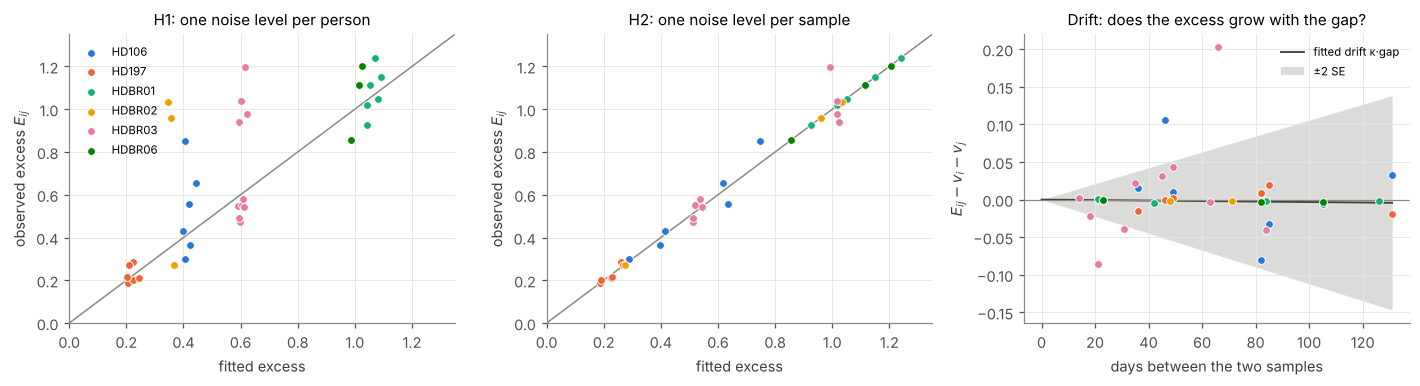

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (H, lab) in enumerate([(H1, 'H1: one noise level per person'),
                              (H2, 'H2: one noise level per sample')]):
    ax = axes[k]
    for p in DONORS:
        m = (pw['patient'] == p).to_numpy()
        ax.scatter(H['fitted'][m], pw['excess'][m], color=COLOR[p], s=26, edgecolor='white',
                   linewidth=0.6, label=short(p), zorder=3)
    lim = [0, 1.35]
    ax.plot(lim, lim, color=GREY, lw=1)
    ax.set(xlim=lim, ylim=lim, xlabel='fitted excess', ylabel='observed excess $E_{ij}$',
           title=lab)
axes[0].legend(fontsize=7.5)
# drift: residual excess after removing the sample terms, against the gap
resid = pw['excess'].to_numpy() - (H2['fitted'] - H2['beta'][-1] * pw['gap_days'].to_numpy())
ax = axes[2]
for p in DONORS:
    m = (pw['patient'] == p).to_numpy()
    ax.scatter(pw['gap_days'][m], resid[m], color=COLOR[p], s=26, edgecolor='white',
               linewidth=0.6, zorder=3)
gg = np.linspace(0, pw['gap_days'].max(), 50)
ax.plot(gg, H2['beta'][-1] * gg, color='#3d3c39', lw=1.2, label='fitted drift κ·gap')
ax.fill_between(gg, (H2['beta'][-1] - 2 * H2['se'][-1]) * gg,
                (H2['beta'][-1] + 2 * H2['se'][-1]) * gg, color=GREY, alpha=0.3, lw=0,
                label='±2 SE')
ax.axhline(0, color=GREY, lw=0.8)
ax.set(xlabel='days between the two samples', ylabel='$E_{ij} - v_i - v_j$',
       title='Drift: does the excess grow with the gap?')
ax.legend(fontsize=7.5)
fig.tight_layout()

**Link to the likelihood estimates.** Section 2 estimates a per-sample dispersion
$\phi_t$ by maximum likelihood (truncated NB, Cox–Reid). The model-free noise levels $v_t$
and the likelihood $\phi_t$ should rank the samples the same way ($v_t$ large ↔ $\phi_t$
small).

Spearman, v_t vs 1/phi_t, all samples             : 0.93  (p = 2.1e-10)
Spearman, within-person relative noise (both scales): 0.54  (p = 8.1e-03)


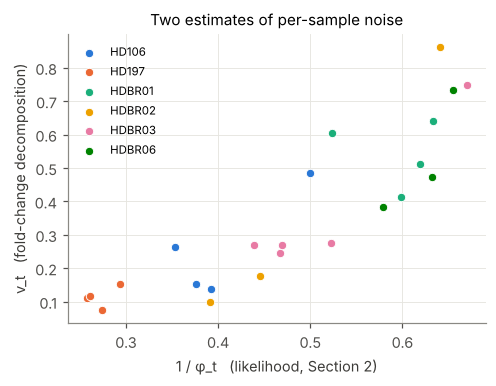

In [17]:
m = v_t.merge(ps_don[['patient', 'day', 'phi_sample', 'rel']], on=['patient', 'day'])
rho_all = stats.spearmanr(m['v_t'], 1 / m['phi_sample'])
rho_within = stats.spearmanr(m['v_rel'], m['rel'])
print(f"Spearman, v_t vs 1/phi_t, all samples             : {rho_all.statistic:.2f}"
      f"  (p = {rho_all.pvalue:.1e})")
print(f"Spearman, within-person relative noise (both scales): {rho_within.statistic:.2f}"
      f"  (p = {rho_within.pvalue:.1e})")

fig, ax = plt.subplots(figsize=(4.6, 3.6))
for p in DONORS:
    s = m[m['patient'] == p]
    ax.scatter(1 / s['phi_sample'], s['v_t'], color=COLOR[p], s=30, edgecolor='white',
               linewidth=0.6, label=short(p), zorder=3)
ax.set(xlabel='1 / φ_t   (likelihood, Section 2)', ylabel='v_t   (fold-change decomposition)',
       title='Two estimates of per-sample noise')
ax.legend(fontsize=7.5)
fig.tight_layout()

**What this shows.**

* **The counts are overdispersed** (H0 rejected). The excess over read sampling is
  0.19–1.24 in log-variance, against a read-sampling term of 0.003–0.016: for an abundant
  clone, a single sample moves its apparent frequency by a factor of about $e^{\pm 0.3}$
  to $e^{\pm 0.9}$ (one SD, $\sqrt{v_t}$). This is why the model is a **negative binomial**, whose variance has the
  quadratic term $\mu^2/\phi$, rather than a Poisson.
* **The noise is a property of the sample, not of the person.** A single level per person
  (H1) fits poorly (left panel); one level per sample (H2) fits the 34 pairs closely
  (middle), and the improvement is significant (F-test above). Within a person, $v_t$
  differs by up to about 8-fold: HDBR02 day 48 (0.86 vs 0.10 and 0.18 for days 0 and 71),
  HDBR03 day 0 (0.75 vs about 0.26 for its other four samples), HD106 day 0 (0.48 vs
  0.14–0.26). With a single $\phi$ per person, the noise of one bad sample would be
  spread over all of them: too small at the noisy sample (spurious calls whenever a clone
  is measured there) and too large elsewhere (lost power). Hence **per-sample $\phi_t$**
  (Section 2), the count-data analogue of limma's sample quality weights.
* **The two estimates agree.** The model-free $v_t$ and the likelihood $\phi_t$ rank the
  samples almost identically (Spearman 0.93 over all samples; 0.54 for the within-person
  ranking, where the range is narrower). The absolute scales differ, as expected: the MAD
  ignores the tails that the likelihood uses, and the two use different clone subsets.
* **No detectable drift in healthy donors.** The excess does not grow with the time
  between samples (right panel): $\kappa$ is indistinguishable from zero (estimate and SE
  above). Over the donors' 3–4 months, the differences between samples are explained by
  per-sample noise, not by clones wandering in frequency. A **constant-frequency null**
  is therefore adequate for donors. Caveat: the donors span at most 131 days and the
  patients about a year, so a slow drift on yearly timescales cannot be excluded from
  these data; the 2-SE upper bound on $\kappa$ corresponds to a drift variance of about
  0.1 per 100 days.
* **The offsets are accurate to about 20 %.** The median log fold change of abundant
  clones (`median_d`) stays within ±0.2 for every pair. TMM centres the bulk of shared
  clones, which are mostly small; a residual shift of this size for the abundant ones is
  part of the per-sample noise that $\phi_t$ absorbs.

## 1.7 Summary: what the donor data decide

| Observation (section) | Decision | Where |
|---|---|---|
| Every sample is cut at $c_t = \lceil 10^{-6} D_t \rceil$; the count distribution is cut while rising (1.2) | Donor dispersion from the NB **truncated** at $c_t$; in patients a miss is **censored**, $P(X < c_t)$, not a zero | Sections 2–3 |
| 70–94 % of clonotypes are within 10× of the cutoff (1.3) | $\phi$ estimated from clones ≥ 10× cutoff; test restricted to average frequency ≥ 1e-5 | Sections 2, 4 |
| Recapture far below what read sampling predicts (1.4) | A cell-sampling **dropout** term $e^{-N_t\lambda}$, $N_t$ estimated per sample; donors fitted on detected counts only | Section 3 |
| Healthy samples stay within ~3× of their siblings on every QC metric; failed libraries fail several metrics by 1–2 orders of magnitude (1.5) | QC relative to the same person, thresholds 0.2 / 5 / 5 / 0.6, drop at ≥ 2 failures | applied to all data |
| Excess variance ≫ read sampling (1.6) | **Negative binomial** | all |
| Noise differs between samples of the same person; one level per person fits poorly (1.6) | **Per-sample $\phi_t$**, with the noisiest donor as a floor for patients | Section 2 |
| No drift detectable in donors over 3–4 months (1.6) | **Constant-frequency** null | Section 4 |

**References** for the precedents mentioned:

* Ritchie ME et al. (2006). Empirical array quality weights in the analysis of microarray
  data. *BMC Bioinformatics* 7:261.
* Liu R et al. (2015). Why weight? Modelling sample and observational level variability
  improves power in RNA-seq analyses. *Nucleic Acids Res* 43:e97.
* Bourgon R, Gentleman R, Huber W (2010). Independent filtering increases detection power
  for high-throughput experiments. *PNAS* 107:9546–9551.